In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
!pip -q install scikit-image

import os
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from skimage.feature import hog

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

START = time.time()

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
print("ACTIVITY 1: DATASET COLLECTION")

DATASET_PATH = Path(
    "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset"
)

CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]

CLASS_NAMES = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]

CLASS_MAP = {name: i for i, name in enumerate(CLASSES)}

EXTENSIONS = [".jpg", ".jpeg", ".png", ".bmp"]

def normalize_class(name):
    name = name.lower().replace("_", "").replace("-", "").replace(" ", "")
    return name if name in CLASSES else None

train_dirs = [
    p for p in DATASET_PATH.rglob("*")
    if p.is_dir() and p.name.lower() == "training"
]

test_dirs = [
    p for p in DATASET_PATH.rglob("*")
    if p.is_dir() and p.name.lower() == "testing"
]

def get_class_folders(folder):
    result = {}
    for item in folder.iterdir():
        if item.is_dir():
            cls = normalize_class(item.name)
            if cls:
                result[cls] = item
    return result

selected_pair = None

for tr in train_dirs:
    for te in test_dirs:
        if tr.parent == te.parent:
            if len(get_class_folders(tr)) == 4 and len(get_class_folders(te)) == 4:
                selected_pair = (tr, te)
                break
    if selected_pair:
        break

if selected_pair is None:
    raise FileNotFoundError("Training and Testing folders not found.")

TRAIN_DIR, TEST_DIR = selected_pair

print("Project: Brain Tumor MRI Classification")
print("Training folder:", TRAIN_DIR)
print("Testing folder:", TEST_DIR)
print("Classes:", CLASS_NAMES)

ACTIVITY 1: DATASET COLLECTION
Project: Brain Tumor MRI Classification
Training folder: /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training
Testing folder: /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing
Classes: ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']


In [4]:
def collect_images(folder):
    records = []
    class_folders = get_class_folders(folder)

    for cls in CLASSES:
        for image_path in class_folders[cls].rglob("*"):
            if image_path.suffix.lower() in EXTENSIONS:
                records.append({
                    "image_path": str(image_path),
                    "class": cls,
                    "label": CLASS_MAP[cls]
                })

    return pd.DataFrame(records)

train_df = collect_images(TRAIN_DIR)
test_df = collect_images(TEST_DIR)

print("Training images:", len(train_df))
print("Testing images:", len(test_df))
print("Total images:", len(train_df) + len(test_df))

print("\nTraining class distribution:")
print(train_df["class"].value_counts())

print("\nTesting class distribution:")
print(test_df["class"].value_counts())

Training images: 5600
Testing images: 1600
Total images: 7200

Training class distribution:
class
glioma        1400
meningioma    1400
notumor       1400
pituitary     1400
Name: count, dtype: int64

Testing class distribution:
class
glioma        400
meningioma    400
notumor       400
pituitary     400
Name: count, dtype: int64


In [5]:
print("ACTIVITY 2: DATA CLEANING")

train_df = train_df.drop_duplicates("image_path")
test_df = test_df.drop_duplicates("image_path")

def check_images(data):
    valid = []

    for path in tqdm(data["image_path"]):
        try:
            with Image.open(path) as img:
                img.verify()
            valid.append(True)
        except:
            valid.append(False)

    return data.loc[valid].reset_index(drop=True)

train_df = check_images(train_df)
test_df = check_images(test_df)

print("Valid training images:", len(train_df))
print("Valid testing images:", len(test_df))

ACTIVITY 2: DATA CLEANING


  0%|          | 0/5600 [00:00<?, ?it/s]

  0%|          | 0/1600 [00:00<?, ?it/s]

Valid training images: 5600
Valid testing images: 1600


ACTIVITY 3: EXPLORATORY DATA ANALYSIS
class
glioma        1400
meningioma    1400
notumor       1400
pituitary     1400
Name: count, dtype: int64


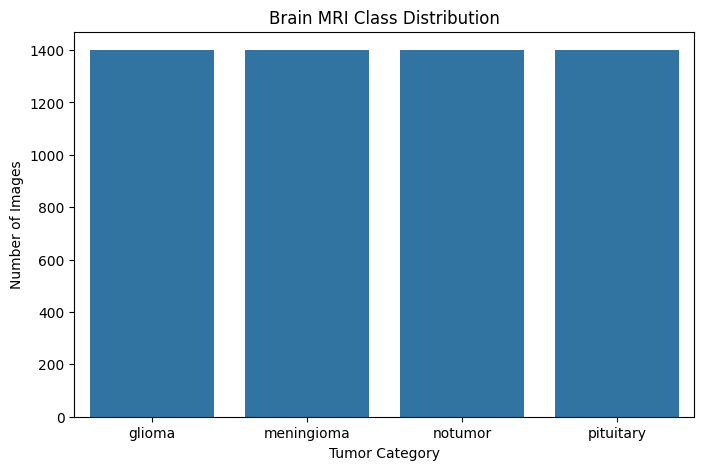

In [6]:
print("ACTIVITY 3: EXPLORATORY DATA ANALYSIS")

print(train_df["class"].value_counts())

plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_df,
    x="class",
    order=CLASSES
)

plt.title("Brain MRI Class Distribution")
plt.xlabel("Tumor Category")
plt.ylabel("Number of Images")
plt.show()

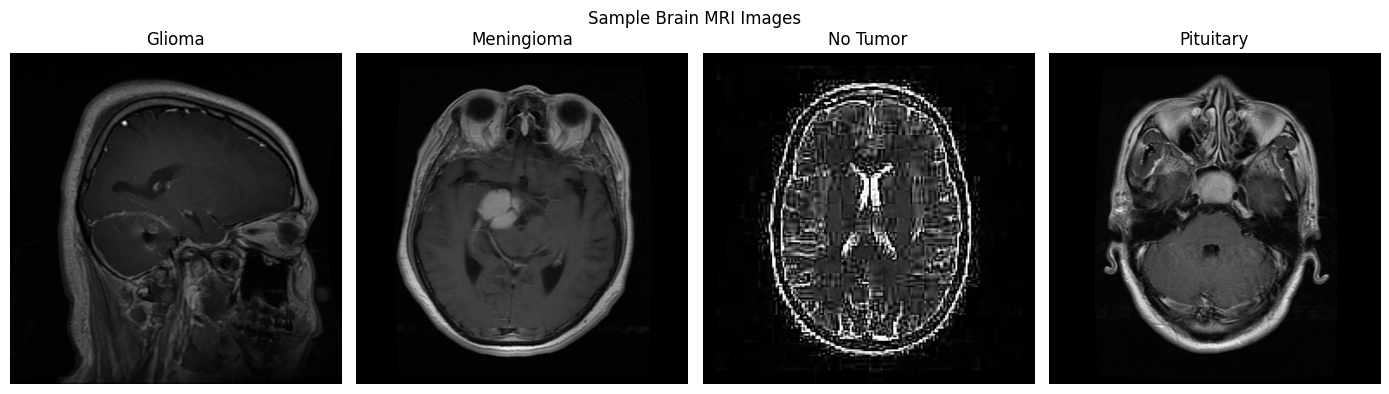

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for i, cls in enumerate(CLASSES):

    sample = train_df[train_df["class"] == cls].iloc[0]

    img = Image.open(sample["image_path"]).convert("RGB")

    axes[i].imshow(img)
    axes[i].set_title(CLASS_NAMES[i])
    axes[i].axis("off")

plt.suptitle("Sample Brain MRI Images")
plt.tight_layout()
plt.show()

In [8]:
print("ACTIVITY 4: IMAGE PREPROCESSING")

IMAGE_SIZE = 64

def extract_features(path):
    try:
        img = Image.open(path).convert("L")
        img = img.resize((IMAGE_SIZE, IMAGE_SIZE))

        arr = np.array(img, dtype=np.float32) / 255.0

        features = hog(
            arr,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            feature_vector=True
        )

        return features

    except:
        return None


def build_features(data, name):
    X = []
    y = []

    print("Extracting:", name)

    for _, row in tqdm(data.iterrows(), total=len(data)):
        feature = extract_features(row["image_path"])

        if feature is not None:
            X.append(feature)
            y.append(row["label"])

    return np.array(X), np.array(y)


X_train_all, y_train_all = build_features(train_df, "Training")
X_test, y_test = build_features(test_df, "Testing")

print("Training feature shape:", X_train_all.shape)
print("Testing feature shape:", X_test.shape)

ACTIVITY 4: IMAGE PREPROCESSING
Extracting: Training


  0%|          | 0/5600 [00:00<?, ?it/s]

Extracting: Testing


  0%|          | 0/1600 [00:00<?, ?it/s]

Training feature shape: (5600, 1764)
Testing feature shape: (1600, 1764)


In [9]:
print("ACTIVITY 5: TRAIN-TEST SPLITTING")

X_train, X_val, y_train, y_val = train_test_split(
    X_train_all,
    y_train_all,
    test_size=0.15,
    random_state=42,
    stratify=y_train_all
)

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))

ACTIVITY 5: TRAIN-TEST SPLITTING
Training records: 4760
Validation records: 840
Testing records: 1600


In [10]:
print("FEATURE SCALING AND FEATURE SELECTION")

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

selector = SelectKBest(
    score_func=f_classif,
    k=min(700, X_train.shape[1])
)

X_train = selector.fit_transform(X_train, y_train)
X_val = selector.transform(X_val)
X_test = selector.transform(X_test)

print("Selected features:", X_train.shape[1])

FEATURE SCALING AND FEATURE SELECTION
Selected features: 700


In [11]:
print("ACTIVITY 6: MACHINE LEARNING MODELS")

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1500,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=25,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        max_depth=30,
        n_jobs=-1,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        n_jobs=-1
    ),

    "SVM": SVC(
        kernel="rbf",
        C=10,
        gamma="scale",
        random_state=42
    )
}

print("Total models:", len(models))

for name in models:
    print(name)

ACTIVITY 6: MACHINE LEARNING MODELS
Total models: 5
Logistic Regression
Decision Tree
Random Forest
KNN
SVM


In [12]:
print("ACTIVITY 7: MODEL TRAINING")
print("ACTIVITY 8: MODEL EVALUATION")

validation_results = []
test_results = []
test_predictions = {}
trained_models = {}

for name, model in models.items():

    print("\nTraining:", name)

    model.fit(X_train, y_train)

    # Validation
    val_pred = model.predict(X_val)

    val_accuracy = accuracy_score(y_val, val_pred) * 100
    val_f1 = f1_score(
        y_val, val_pred, average="macro", zero_division=0
    ) * 100

    validation_results.append({
        "Model": name,
        "Accuracy": val_accuracy,
        "F1 Score": val_f1
    })

    # Testing
    test_pred = model.predict(X_test)

    test_predictions[name] = test_pred
    trained_models[name] = model

    accuracy = accuracy_score(y_test, test_pred) * 100

    precision = precision_score(
        y_test, test_pred, average="macro", zero_division=0
    ) * 100

    recall = recall_score(
        y_test, test_pred, average="macro", zero_division=0
    ) * 100

    f1 = f1_score(
        y_test, test_pred, average="macro", zero_division=0
    ) * 100

    test_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    print("Validation Accuracy:", round(val_accuracy, 2), "%")
    print("Testing Accuracy:", round(accuracy, 2), "%")

ACTIVITY 7: MODEL TRAINING
ACTIVITY 8: MODEL EVALUATION

Training: Logistic Regression
Validation Accuracy: 83.57 %
Testing Accuracy: 78.0 %

Training: Decision Tree
Validation Accuracy: 75.48 %
Testing Accuracy: 72.19 %

Training: Random Forest
Validation Accuracy: 86.19 %
Testing Accuracy: 81.5 %

Training: KNN
Validation Accuracy: 90.48 %
Testing Accuracy: 82.12 %

Training: SVM
Validation Accuracy: 92.86 %
Testing Accuracy: 88.94 %


In [13]:
validation_df = pd.DataFrame(validation_results)

validation_df = validation_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print("VALIDATION RESULTS")

display(validation_df.round(2))

best_model_name = validation_df.iloc[0]["Model"]

print("Best Model:", best_model_name)

VALIDATION RESULTS


,Model,Accuracy,F1 Score
0,SVM,92.86,92.84
1,KNN,90.48,90.37
2,Random Forest,86.19,86.14
3,Logistic Regression,83.57,83.70
4,Decision Tree,75.48,75.51


Best Model: SVM


ACTIVITY 9: CONFUSION MATRIX


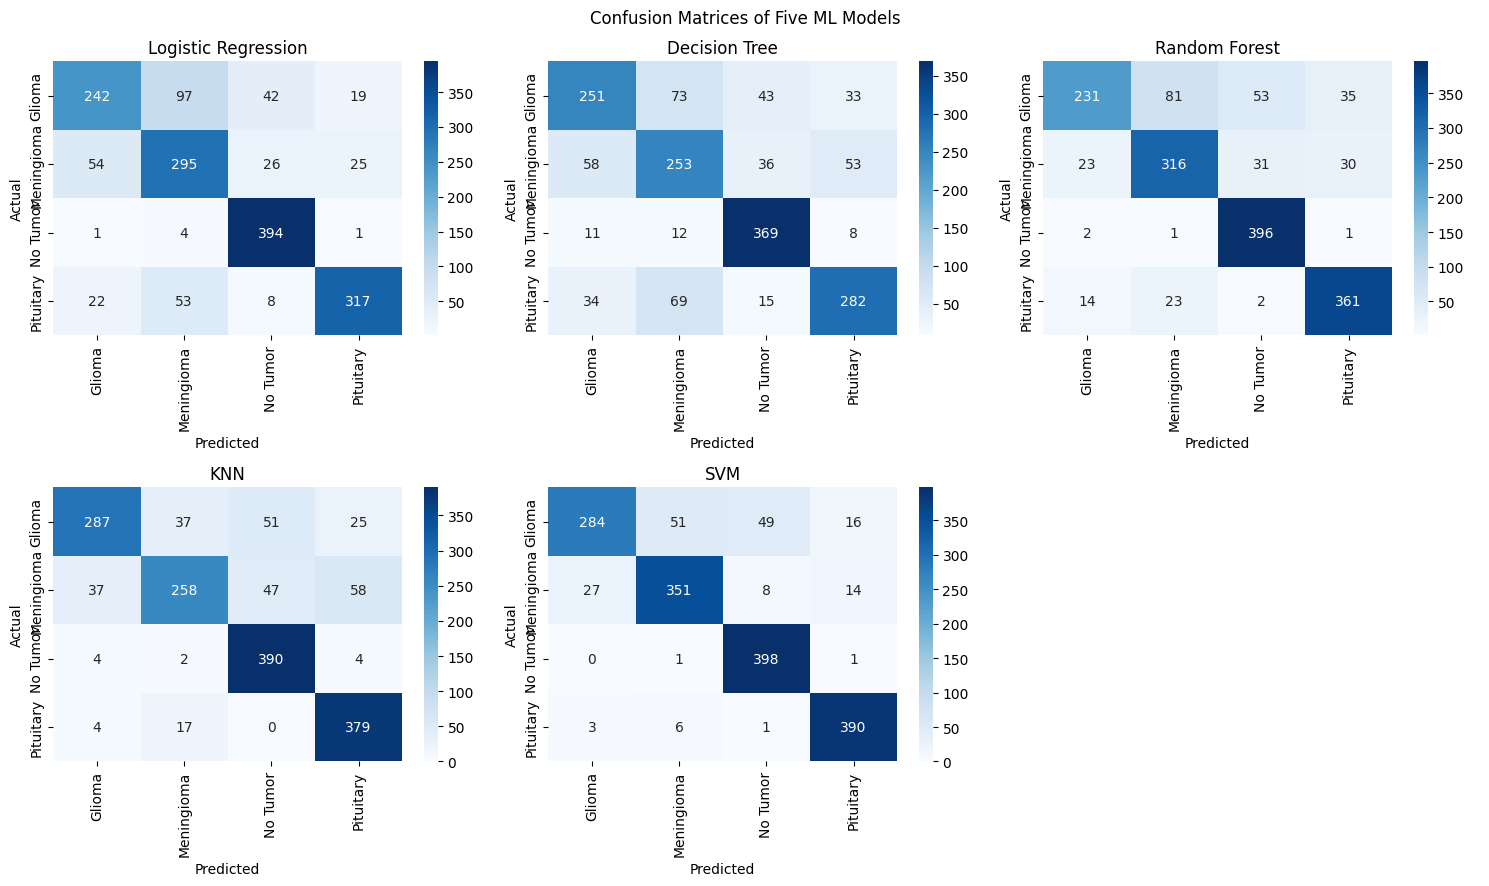

In [14]:
print("ACTIVITY 9: CONFUSION MATRIX")

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, name in enumerate(models):

    cm = confusion_matrix(
        y_test,
        test_predictions[name]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

axes[-1].axis("off")

plt.suptitle("Confusion Matrices of Five ML Models")
plt.tight_layout()
plt.show()

In [15]:
print("ACTIVITY 10: MODEL COMPARISON")

results_df = pd.DataFrame(test_results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

display(results_df.round(2))

ACTIVITY 10: MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,SVM,88.94,89.05,88.94,88.58
1,KNN,82.12,82.46,82.12,81.51
2,Random Forest,81.50,81.83,81.50,80.76
3,Logistic Regression,78.00,78.24,78.00,77.65
4,Decision Tree,72.19,71.94,72.19,71.87


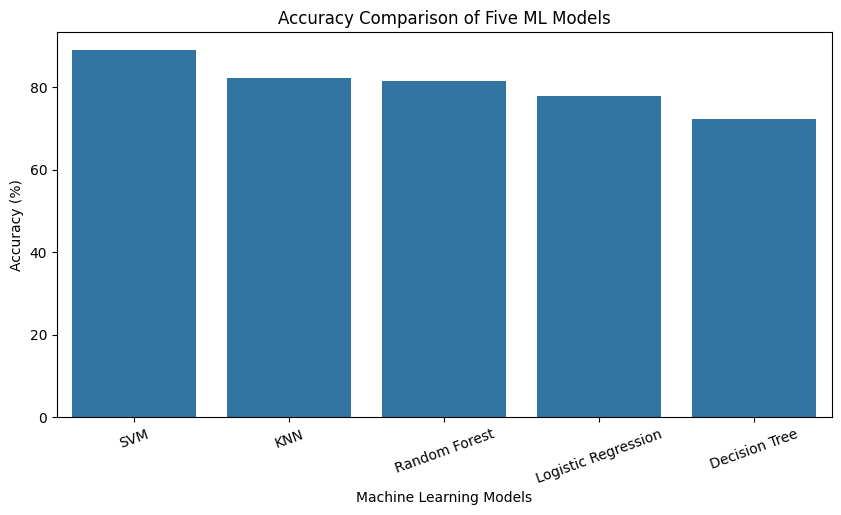

In [16]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison of Five ML Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=20)
plt.show()

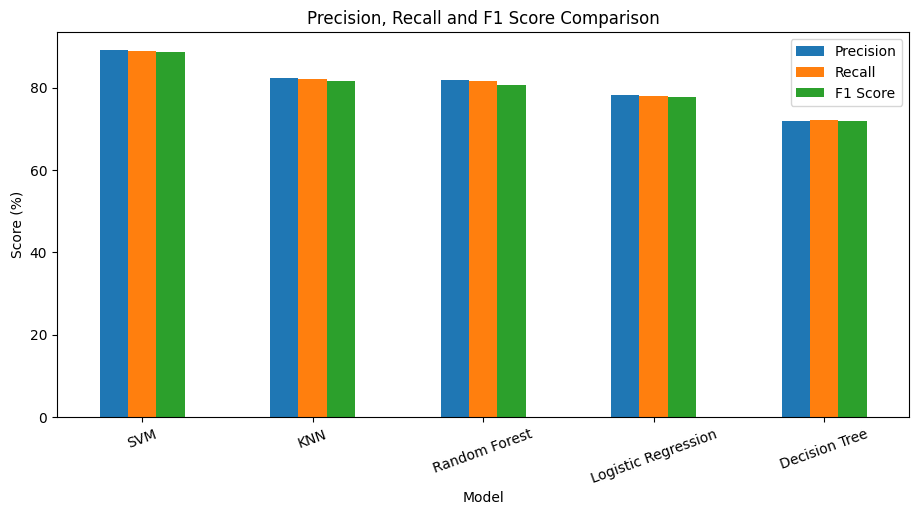

In [17]:
results_df.set_index("Model")[
    ["Precision", "Recall", "F1 Score"]
].plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("Precision, Recall and F1 Score Comparison")
plt.ylabel("Score (%)")
plt.xticks(rotation=20)
plt.show()

In [18]:
print("=" * 60)
print("FINAL PROJECT REPORT")
print("=" * 60)

best_model = trained_models[best_model_name]
best_pred = test_predictions[best_model_name]

best_accuracy = accuracy_score(y_test, best_pred) * 100

print("Project: Brain Tumor MRI Classification")
print("Dataset: Brain Tumor MRI Dataset")
print("Number of Models:", len(models))
print("Best Model:", best_model_name)
print("Best Accuracy:", round(best_accuracy, 2), "%")

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test,
    best_pred,
    target_names=CLASS_NAMES,
    zero_division=0
))

print("\nCONFUSION MATRIX")

print(confusion_matrix(y_test, best_pred))

FINAL PROJECT REPORT
Project: Brain Tumor MRI Classification
Dataset: Brain Tumor MRI Dataset
Number of Models: 5
Best Model: SVM
Best Accuracy: 88.94 %

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Glioma       0.90      0.71      0.80       400
  Meningioma       0.86      0.88      0.87       400
    No Tumor       0.87      0.99      0.93       400
   Pituitary       0.93      0.97      0.95       400

    accuracy                           0.89      1600
   macro avg       0.89      0.89      0.89      1600
weighted avg       0.89      0.89      0.89      1600


CONFUSION MATRIX
[[284  51  49  16]
 [ 27 351   8  14]
 [  0   1 398   1]
 [  3   6   1 390]]


In [20]:
OUTPUT = Path("/kaggle/working")

results_df.to_csv(
    OUTPUT / "model_comparison.csv",
    index=False
)

validation_df.to_csv(
    OUTPUT / "validation_results.csv",
    index=False
)

print("Results saved successfully!")

print("1. model_comparison.csv")
print("2. validation_results.csv")

print("\nTotal Execution Time:",
      round((time.time() - START) / 60, 2), "minutes")

print("\nALL ACTIVITIES COMPLETED!")
print("=" * 60)

Results saved successfully!
1. model_comparison.csv
2. validation_results.csv

Total Execution Time: 5.79 minutes

ALL ACTIVITIES COMPLETED!
